In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

df = pd.read_csv('/content/telecom_churn_raw.csv')

df.head(15)

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41,"Jan 31, 2023",Yes,Yes,Fiber optic,...,One year,Yes,Mailed check,91.26,"$3,869.1",83.3,0,2,Excellent,No
1,TC-11161,Female,1,No,Yes,19,2024-11-30,Yes,Yes,DSL,...,Month-to-month,Yes,Electronic check,67.81,"$1,230.23",16.8,4,2,Poor,Yes
2,TC-10375,Female,0,No,Yes,64,2021/03/03,Yes,Yes,No,...,Two Year,No,Bank transfer,39.46,2428.58,0.0,1,1,Poor,No
3,TC-10362,Female,0,Yes,No,NaN,2023-07-02,yes,Yes,FIBER OPTIC,...,2 year,yes,--,93.6,3497.22,Not Available,1,1,Excellent,No
4,TC-11216,Male,0,Yes,No,24,"Jul 01, 2024",Yes,Yes,DSL,...,Month-to-month,False,Bank transfer,73.94,1710.9,40.6,3,NaN,avg,No
5,TC-10501,Male,0,Yes,No,4,01/03/2026,Yes,No,DSL,...,Month-to-month,No,NaN,64.91,252.83,NaN,4,NaN,NaN,Yes
6,TC-10143,male,0,Yes,No,17,2025-01-30,Yes,No,Fiber optic,...,Month-to-month,No,Electronic check,107.66,1909.15,77.6,3,1,POOR,Yes
7,TC-10791,Male,0,No,No,25,2024-05-31,Yes,Yes,No,...,Month-to-month,No,Bank transfer,33.68,872.93,0.0,3,0,poor,No
8,TC-10035,Female,no,No,No,31,01/12/2023,Yes,Yes,Fiber optic,...,Monthly,No,Credit card,105.25,3299.93,139.3,4,1,poor,Yes
9,TC-10826,Male,0,No,No,13,2025-05-31,Yes,No,Fiber optic,...,Month-to-month,Yes,Bank transfer,82.04,1033.47,200.9,2,0,POOR,Yes


In [51]:
df.dtypes

,0
customer_id,object
gender,object
senior_citizen,object
partner,object
dependents,object
tenure_months,object
signup_date,object
phone_service,object
multiple_lines,object
internet_service,object


In [52]:
df.shape

(1300, 23)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   customer_id            1300 non-null   object
 1   gender                 1272 non-null   object
 2   senior_citizen         1300 non-null   object
 3   partner                1279 non-null   object
 4   dependents             1300 non-null   object
 5   tenure_months          1269 non-null   object
 6   signup_date            1278 non-null   object
 7   phone_service          1300 non-null   object
 8   multiple_lines         1300 non-null   object
 9   internet_service       1273 non-null   object
 10  online_security        1269 non-null   object
 11  tech_support           1273 non-null   object
 12  streaming_tv           1300 non-null   object
 13  contract_type          1279 non-null   object
 14  paperless_billing      1300 non-null   object
 15  payment_method       

In [54]:
df.describe()

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
count,1300,1272,1300,1279,1300,1269,1278,1300,1300,1273,...,1279,1300,1260,1266,1273,1237,1255,1258,1228,1291
unique,1251,13,6,14,12,87,233,12,3,11,...,14,12,17,1087,1212,722,14,10,33,14
top,TC-10878,Female,0,Yes,No,12,2024-07-01,Yes,No,Fiber optic,...,Month-to-month,Yes,Electronic check,18.25,?,0.0,1,0,Average,No
freq,2,562,1006,604,825,45,29,1056,575,514,...,645,664,387,25,7,235,359,575,287,815


In [55]:
df.isnull().sum()

,0
customer_id,0
gender,28
senior_citizen,0
partner,21
dependents,0
tenure_months,31
signup_date,22
phone_service,0
multiple_lines,0
internet_service,27


In [56]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


In [57]:
df.isnull().sum()

,0
customer_id,0
gender,0
senior_citizen,0
partner,0
dependents,0
tenure_months,0
signup_date,0
phone_service,0
multiple_lines,0
internet_service,0


In [58]:
df.duplicated().sum()

np.int64(35)

In [59]:
df = df.drop_duplicates()

In [60]:
df.duplicated().sum()

np.int64(0)

In [61]:
df["gender"].unique()

array(['Female', 'Male', 'male', 'Male ', 'Not Available', 'fem',
       'FEMALE', 'MALE', 'M', 'female', 'F', 'FEM', '--'], dtype=object)

In [62]:
df["partner"].unique()

array(['Yes', 'No', 'N', 'yes', '0', 'NO', 'no', 'Y', 'True', '1', '--',
       'False', 'YES', 'Not Available'], dtype=object)

In [63]:
df["dependents"].unique()

array(['Yes', 'No', 'N', 'False', '0', 'True', 'no', 'NO', '1', 'Y',
       'yes', 'YES'], dtype=object)

In [64]:
df["phone_service"].unique()

array(['Yes', 'yes', 'True', 'No', 'Y', '1', 'YES', 'NO', 'no', 'N',
       'False', '0'], dtype=object)

In [65]:
df["multiple_lines"].unique()

array(['Yes', 'No', 'No phone service'], dtype=object)

In [66]:
df["churn"].unique()

array(['No', 'Yes', 'N', 'Churned', 'NO', 'no', '--', '0', 'YES', 'Y',
       'Stayed', 'yes', 'Not Available', '1'], dtype=object)

In [67]:
df.head(20)

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41,"Jan 31, 2023",Yes,Yes,Fiber optic,...,One year,Yes,Mailed check,91.26,"$3,869.1",83.3,0,2,Excellent,No
1,TC-11161,Female,1,No,Yes,19,2024-11-30,Yes,Yes,DSL,...,Month-to-month,Yes,Electronic check,67.81,"$1,230.23",16.8,4,2,Poor,Yes
2,TC-10375,Female,0,No,Yes,64,2021/03/03,Yes,Yes,No,...,Two Year,No,Bank transfer,39.46,2428.58,0.0,1,1,Poor,No
3,TC-10362,Female,0,Yes,No,12,2023-07-02,yes,Yes,FIBER OPTIC,...,2 year,yes,--,93.6,3497.22,Not Available,1,1,Excellent,No
4,TC-11216,Male,0,Yes,No,24,"Jul 01, 2024",Yes,Yes,DSL,...,Month-to-month,False,Bank transfer,73.94,1710.9,40.6,3,0,avg,No
5,TC-10501,Male,0,Yes,No,4,01/03/2026,Yes,No,DSL,...,Month-to-month,No,Electronic check,64.91,252.83,0.0,4,0,Average,Yes
6,TC-10143,male,0,Yes,No,17,2025-01-30,Yes,No,Fiber optic,...,Month-to-month,No,Electronic check,107.66,1909.15,77.6,3,1,POOR,Yes
7,TC-10791,Male,0,No,No,25,2024-05-31,Yes,Yes,No,...,Month-to-month,No,Bank transfer,33.68,872.93,0.0,3,0,poor,No
8,TC-10035,Female,no,No,No,31,01/12/2023,Yes,Yes,Fiber optic,...,Monthly,No,Credit card,105.25,3299.93,139.3,4,1,poor,Yes
9,TC-10826,Male,0,No,No,13,2025-05-31,Yes,No,Fiber optic,...,Month-to-month,Yes,Bank transfer,82.04,1033.47,200.9,2,0,POOR,Yes


In [68]:
df["senior_citizen"] = df["senior_citizen"].str.strip().replace({
    "Yes": 1,
    "No": 0,
    "no": 0,
    "yes": 1
})

df["churn"] = df["churn"].str.strip().replace({
    "Yes": 1,
    "No": 0,
    "no": 0,
    "yes": 1
})

In [69]:
df.head(15)

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41,"Jan 31, 2023",Yes,Yes,Fiber optic,...,One year,Yes,Mailed check,91.26,"$3,869.1",83.3,0,2,Excellent,0
1,TC-11161,Female,1,No,Yes,19,2024-11-30,Yes,Yes,DSL,...,Month-to-month,Yes,Electronic check,67.81,"$1,230.23",16.8,4,2,Poor,1
2,TC-10375,Female,0,No,Yes,64,2021/03/03,Yes,Yes,No,...,Two Year,No,Bank transfer,39.46,2428.58,0.0,1,1,Poor,0
3,TC-10362,Female,0,Yes,No,12,2023-07-02,yes,Yes,FIBER OPTIC,...,2 year,yes,--,93.6,3497.22,Not Available,1,1,Excellent,0
4,TC-11216,Male,0,Yes,No,24,"Jul 01, 2024",Yes,Yes,DSL,...,Month-to-month,False,Bank transfer,73.94,1710.9,40.6,3,0,avg,0
5,TC-10501,Male,0,Yes,No,4,01/03/2026,Yes,No,DSL,...,Month-to-month,No,Electronic check,64.91,252.83,0.0,4,0,Average,1
6,TC-10143,male,0,Yes,No,17,2025-01-30,Yes,No,Fiber optic,...,Month-to-month,No,Electronic check,107.66,1909.15,77.6,3,1,POOR,1
7,TC-10791,Male,0,No,No,25,2024-05-31,Yes,Yes,No,...,Month-to-month,No,Bank transfer,33.68,872.93,0.0,3,0,poor,0
8,TC-10035,Female,0,No,No,31,01/12/2023,Yes,Yes,Fiber optic,...,Monthly,No,Credit card,105.25,3299.93,139.3,4,1,poor,1
9,TC-10826,Male,0,No,No,13,2025-05-31,Yes,No,Fiber optic,...,Month-to-month,Yes,Bank transfer,82.04,1033.47,200.9,2,0,POOR,1


In [70]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Columns:")
print(df.columns.tolist())

df.info()

df.head()

Missing values:
customer_id              0
gender                   0
senior_citizen           0
partner                  0
dependents               0
tenure_months            0
signup_date              0
phone_service            0
multiple_lines           0
internet_service         0
online_security          0
tech_support             0
streaming_tv             0
contract_type            0
paperless_billing        0
payment_method           0
monthly_charges          0
total_charges            0
avg_monthly_gb           0
support_calls            0
late_payments            0
customer_satisfaction    0
churn                    0
dtype: int64
Duplicate rows: 0
Columns:
['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months', 'signup_date', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'tech_support', 'streaming_tv', 'contract_type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'avg_monthly_gb', 'suppo

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41,"Jan 31, 2023",Yes,Yes,Fiber optic,...,One year,Yes,Mailed check,91.26,"$3,869.1",83.3,0,2,Excellent,0
1,TC-11161,Female,1,No,Yes,19,2024-11-30,Yes,Yes,DSL,...,Month-to-month,Yes,Electronic check,67.81,"$1,230.23",16.8,4,2,Poor,1
2,TC-10375,Female,0,No,Yes,64,2021/03/03,Yes,Yes,No,...,Two Year,No,Bank transfer,39.46,2428.58,0.0,1,1,Poor,0
3,TC-10362,Female,0,Yes,No,12,2023-07-02,yes,Yes,FIBER OPTIC,...,2 year,yes,--,93.6,3497.22,Not Available,1,1,Excellent,0
4,TC-11216,Male,0,Yes,No,24,"Jul 01, 2024",Yes,Yes,DSL,...,Month-to-month,False,Bank transfer,73.94,1710.9,40.6,3,0,avg,0


In [71]:
for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip().str.lower()

df = df.drop_duplicates()


df["signup_date"] = pd.to_datetime(df["signup_date"], errors="coerce")


df = df.fillna(0)


df.head()



/tmp/ipykernel_3232/1711716940.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["signup_date"] = pd.to_datetime(df["signup_date"], errors="coerce")


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,tc-10348,female,0,yes,yes,41,2023-01-31 00:00:00,yes,yes,fiber optic,...,one year,yes,mailed check,91.26,"$3,869.1",83.3,0,2,excellent,0
1,tc-11161,female,1,no,yes,19,2024-11-30 00:00:00,yes,yes,dsl,...,month-to-month,yes,electronic check,67.81,"$1,230.23",16.8,4,2,poor,0
2,tc-10375,female,0,no,yes,64,2021-03-03 00:00:00,yes,yes,no,...,two year,no,bank transfer,39.46,2428.58,0.0,1,1,poor,0
3,tc-10362,female,0,yes,no,12,2023-07-02 00:00:00,yes,yes,fiber optic,...,2 year,yes,--,93.6,3497.22,not available,1,1,excellent,0
4,tc-11216,male,0,yes,no,24,2024-07-01 00:00:00,yes,yes,dsl,...,month-to-month,false,bank transfer,73.94,1710.9,40.6,3,0,avg,0


In [72]:
df.dtypes

,0
customer_id,object
gender,object
senior_citizen,object
partner,object
dependents,object
tenure_months,object
signup_date,object
phone_service,object
multiple_lines,object
internet_service,object


In [73]:
df.to_csv("telecom_churn_cleaned.csv", index=False)

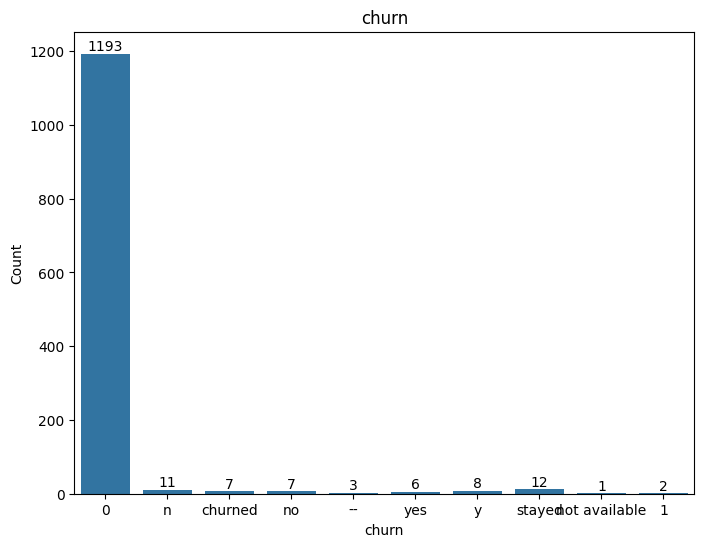

In [74]:
plt.figure(figsize = (8,6))

a = sns.countplot(
    data = df,
    x = "churn"
)

plt.title("churn")
plt.xlabel("churn")
plt.ylabel("Count")


for container in a.containers:
  a.bar_label(container)

plt.show()

/tmp/ipykernel_3232/4277520500.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


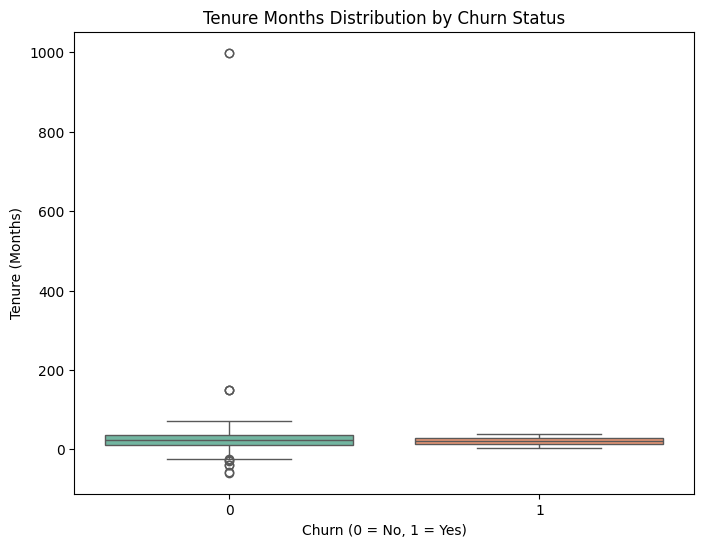

In [75]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df['churn'] = df['churn'].astype(str).str.strip().str.lower()
churn_mapping = {
    '1': 1, 'yes': 1, 'churned': 1, 'y': 1,
    '0': 0, 'no': 0, 'stayed': 0, 'n': 0, '--': 0, 'not available': 0
}
df['churn_numeric'] = df['churn'].map(churn_mapping).fillna(0).astype(int)

df['tenure_months_numeric'] = pd.to_numeric(df['tenure_months'], errors='coerce').fillna(0)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df,
    x='churn_numeric',
    y='tenure_months_numeric',
    palette='Set2'
)

plt.title('Tenure Months Distribution by Churn Status')
plt.xlabel('Churn (0 = No, 1 = Yes)')
plt.ylabel('Tenure (Months)')
plt.show()

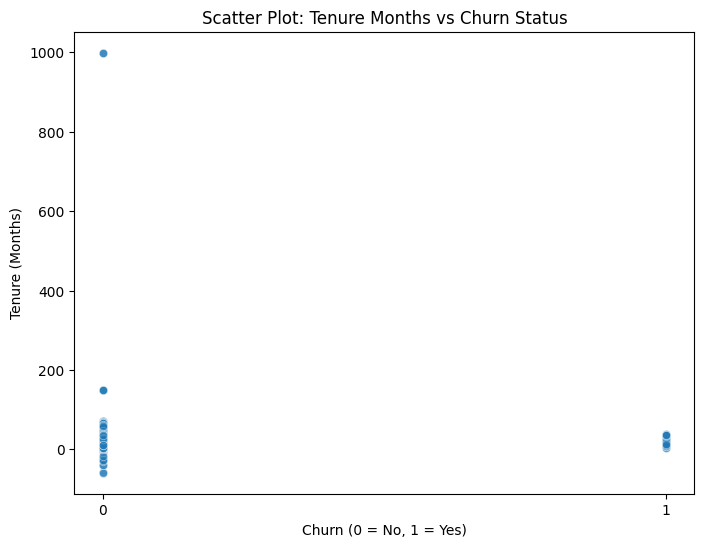

In [76]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


df['churn'] = df['churn'].astype(str).str.strip().str.lower()
churn_mapping = {
    '1': 1, 'yes': 1, 'churned': 1, 'y': 1,
    '0': 0, 'no': 0, 'stayed': 0, 'n': 0, '--': 0, 'not available': 0
}
df['churn_numeric'] = df['churn'].map(churn_mapping).fillna(0).astype(int)


df['tenure_months_numeric'] = pd.to_numeric(df['tenure_months'], errors='coerce').fillna(0)


plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='churn_numeric',
    y='tenure_months_numeric',
    alpha=0.6
)

plt.title('Scatter Plot: Tenure Months vs Churn Status')
plt.xlabel('Churn (0 = No, 1 = Yes)')
plt.ylabel('Tenure (Months)')
plt.xticks([0, 1])
plt.show()

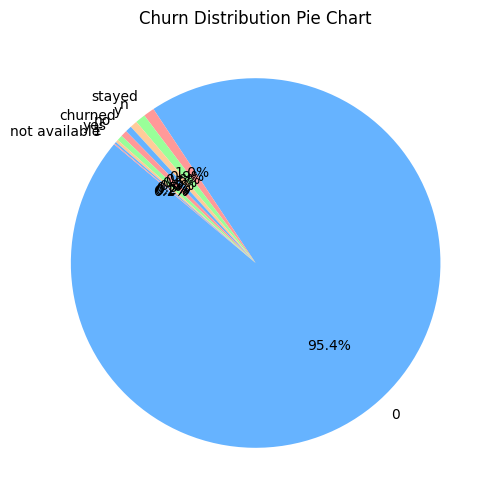

In [77]:
import matplotlib.pyplot as plt


churn_counts = df['churn'].value_counts()


plt.figure(figsize=(8, 6))
plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#66b3ff', '#ff9999', '#99ff99', '#ffcc99']
)

plt.title("Churn Distribution Pie Chart")
plt.show()

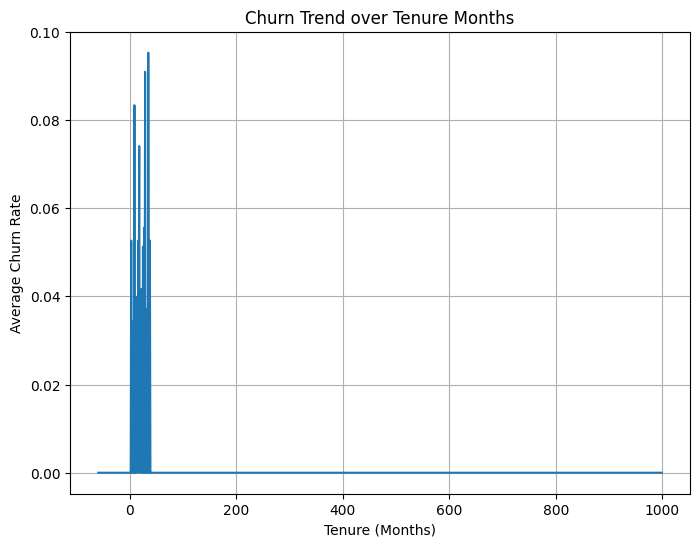

In [78]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


df['churn'] = df['churn'].astype(str).str.strip().str.lower()
churn_mapping = {
    '1': 1, 'yes': 1, 'churned': 1, 'y': 1,
    '0': 0, 'no': 0, 'stayed': 0, 'n': 0, '--': 0, 'not available': 0
}
df['churn_numeric'] = df['churn'].map(churn_mapping).fillna(0).astype(int)


df['tenure_months_numeric'] = pd.to_numeric(df['tenure_months'], errors='coerce').fillna(0)


plt.figure(figsize=(8, 6))
sns.lineplot(
    data=df.sort_values('tenure_months_numeric'),
    x='tenure_months_numeric',
    y='churn_numeric',
    errorbar=None
)

plt.title("Churn Trend over Tenure Months")
plt.xlabel("Tenure (Months)")
plt.ylabel("Average Churn Rate")
plt.grid(True)
plt.show()

In [79]:
df.head(10)

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn,churn_numeric,tenure_months_numeric
0,tc-10348,female,0,yes,yes,41,2023-01-31 00:00:00,yes,yes,fiber optic,...,mailed check,91.26,"$3,869.1",83.3,0,2,excellent,0,0,41.0
1,tc-11161,female,1,no,yes,19,2024-11-30 00:00:00,yes,yes,dsl,...,electronic check,67.81,"$1,230.23",16.8,4,2,poor,0,0,19.0
2,tc-10375,female,0,no,yes,64,2021-03-03 00:00:00,yes,yes,no,...,bank transfer,39.46,2428.58,0.0,1,1,poor,0,0,64.0
3,tc-10362,female,0,yes,no,12,2023-07-02 00:00:00,yes,yes,fiber optic,...,--,93.6,3497.22,not available,1,1,excellent,0,0,12.0
4,tc-11216,male,0,yes,no,24,2024-07-01 00:00:00,yes,yes,dsl,...,bank transfer,73.94,1710.9,40.6,3,0,avg,0,0,24.0
5,tc-10501,male,0,yes,no,4,2026-01-03 00:00:00,yes,no,dsl,...,electronic check,64.91,252.83,0.0,4,0,average,0,0,4.0
6,tc-10143,male,0,yes,no,17,2025-01-30 00:00:00,yes,no,fiber optic,...,electronic check,107.66,1909.15,77.6,3,1,poor,0,0,17.0
7,tc-10791,male,0,no,no,25,2024-05-31 00:00:00,yes,yes,no,...,bank transfer,33.68,872.93,0.0,3,0,poor,0,0,25.0
8,tc-10035,female,0,no,no,31,2023-01-12 00:00:00,yes,yes,fiber optic,...,credit card,105.25,3299.93,139.3,4,1,poor,0,0,31.0
9,tc-10826,male,0,no,no,13,2025-05-31 00:00:00,yes,no,fiber optic,...,bank transfer,82.04,1033.47,200.9,2,0,poor,0,0,13.0


In [80]:
features = [
    "churn",
    "total_charges"
]

In [81]:
x = df[features]
y = df["churn"].map({
    "Fail": 0,
    "Pass": 1
})

In [82]:
x_train,x_test,y_train,y_test = train_test_split(x, y,test_size=0.2,random_state=42)

In [83]:
def evaluate_model (name, model, x_train, x_test, y_train, y_test):

  model.fit(x_train, y_train)

  predictions = model.predict(x_test)

  mae = mean_absolute_error(y_test, predictions)

  rmse = np.sqrt(

  mean_squared_error(y_test, predictions)
  )
  r2 = r2_score (y_test, predictions)

  print(f"\n{name}")
  print("-" * 40)
  print (f"MAE: {mae:.2f}")
  print (f"RMSE {rmse:.2f}")
  print (f"R2 : {r2:.4f}")

  return model, predictions

In [84]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# 1. Properly clean 'total_charges' into numeric floats
df['total_charges_cleaned'] = (
    df['total_charges']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace('?', 'nan', regex=False)
)
df['total_charges_numeric'] = pd.to_numeric(df['total_charges_cleaned'], errors='coerce').fillna(0)

# 2. Re-define features and targets using clean numeric representations
x = df[['total_charges_numeric']]
y = df['churn_numeric']  # Using the numeric target column you already generated

# 3. Re-split the dataset
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# 4. Instantiate and evaluate model
rf = RandomForestRegressor(
    n_estimators=150,
    max_depth=18,
    random_state=42,
    n_jobs=-1
)
rf, rf_pred = evaluate_model(
    "Random Forest",
    rf,
    x_train,
    x_test,
    y_train,
    y_test
)


Random Forest
----------------------------------------
MAE: 0.02
RMSE 0.12
R2 : -0.3149


In [85]:
from xgboost import XGBRegressor

xgboost = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42
)

xgboost, xgboost_pred = evaluate_model(
    "XGBoost",
    xgboost,
    x_train,
    x_test,
    y_train,
    y_test
)


XGBoost
----------------------------------------
MAE: 0.03
RMSE 0.12
R2 : -0.2063


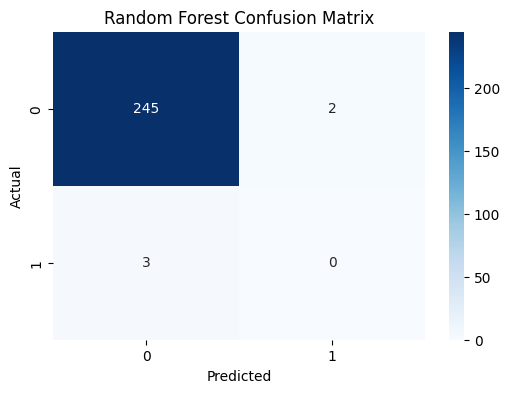

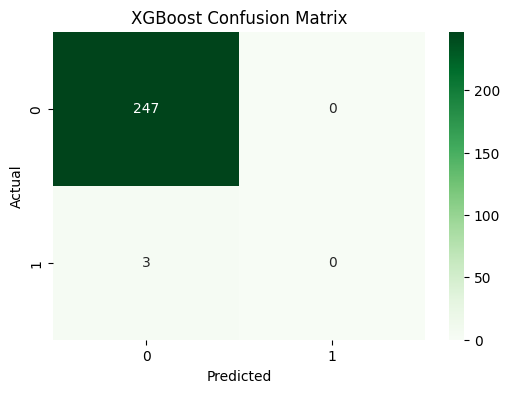

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Convert continuous predictions to binary (0 or 1) using a 0.5 threshold
y_pred_rf_class = (rf.predict(x_test) >= 0.5).astype(int)
y_pred_xgb_class = (xgboost.predict(x_test) >= 0.5).astype(int)

# Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf_class)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# XGBoost confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb_class)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Greens")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [87]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Convert continuous predictions to binary (0 or 1) using a 0.5 threshold
y_pred_rf = (rf.predict(x_test) >= 0.5).astype(int)
y_pred_xgb = (xgboost.predict(x_test) >= 0.5).astype(int)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],

    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],

    "XGBoost": [
        accuracy_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb, zero_division=0),
        recall_score(y_test, y_pred_xgb, zero_division=0),
        f1_score(y_test, y_pred_xgb, zero_division=0)
    ]
})

print(results.round(3))

      Metric  Random Forest  XGBoost
0   Accuracy           0.98    0.988
1  Precision           0.00    0.000
2     Recall           0.00    0.000
3   F1-score           0.00    0.000


In [88]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Random Forest": rf,
    "XGBoost": xgboost
}

results = []

for name, model in models.items():
    # Convert the continuous regressor predictions to binary labels using a 0.5 threshold
    pred = (model.predict(x_test) >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

final_table = pd.DataFrame(results)

print(final_table.round(3))

           Model  Accuracy  Precision  Recall  F1-score
0  Random Forest     0.980        0.0     0.0       0.0
1        XGBoost     0.988        0.0     0.0       0.0


**Final Model Comparison and Selection**

The models were compared using accuracy, precision, recall, and F1-score. These metrics helped evaluate their performance in predicting customer churn.

**I selected XGboost as my final model because it provided a good accuracy&#x20;**


In [89]:
import joblib
joblib.dump(xgboost, 'XGboost_model.pkl')

['XGboost_model.pkl']

In [95]:

#@title Telecom Customer Churn Prediction Form

gender = "Female" #@param ["Female", "Male"]
partner = "Yes" #@param ["Yes", "No"]
tenure_months = 12 #@param {type:"number"}
monthly_charges = 60.0 #@param {type:"number"}
total_charges = 840.0 #@param {type:"number"}
internet_service = "Fiber optic" #@param ["DSL", "Fiber optic", "No"]
payment_method = "Electronic check" #@param ["Electronic check", "Mailed check", "Bank transfer", "Credit card"]
contract_type = "Month-to-month" #@param ["Month-to-month", "One year", "Two year"]

import pandas as pd
import numpy as np

# Create customer input containing ONLY the feature our model was trained on
input_data = pd.DataFrame([{
    "total_charges_numeric": total_charges
}])

# Get continuous prediction from the regressor
raw_prediction = xgboost.predict(input_data)[0]

# Use a 0.5 threshold to classify
prediction = 1 if raw_prediction >= 0.5 else 0

print("Churn Prediction:", "Yes" if prediction == 1 else "No")
print(f"Raw Continuous Prediction Value: {raw_prediction:.4f}")

Churn Prediction: No
Raw Continuous Prediction Value: 0.0008
